In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

rng = np.random.default_rng(42)

## Partie I — Simulation de la convergence uniforme


### 1. Le risque empirique comme variable aléatoire

p=0.1, m= 10: moyenne empirique=0.0990, moyenne théorique=0.1000, écart-type empirique=0.0949
p=0.1, m= 50: moyenne empirique=0.1004, moyenne théorique=0.1000, écart-type empirique=0.0427
p=0.1, m=200: moyenne empirique=0.1001, moyenne théorique=0.1000, écart-type empirique=0.0212
p=0.3, m= 10: moyenne empirique=0.3008, moyenne théorique=0.3000, écart-type empirique=0.1452
p=0.3, m= 50: moyenne empirique=0.3000, moyenne théorique=0.3000, écart-type empirique=0.0645
p=0.3, m=200: moyenne empirique=0.3002, moyenne théorique=0.3000, écart-type empirique=0.0324
p=0.6, m= 10: moyenne empirique=0.6007, moyenne théorique=0.6000, écart-type empirique=0.1552
p=0.6, m= 50: moyenne empirique=0.6005, moyenne théorique=0.6000, écart-type empirique=0.0698
p=0.6, m=200: moyenne empirique=0.6000, moyenne théorique=0.6000, écart-type empirique=0.0351


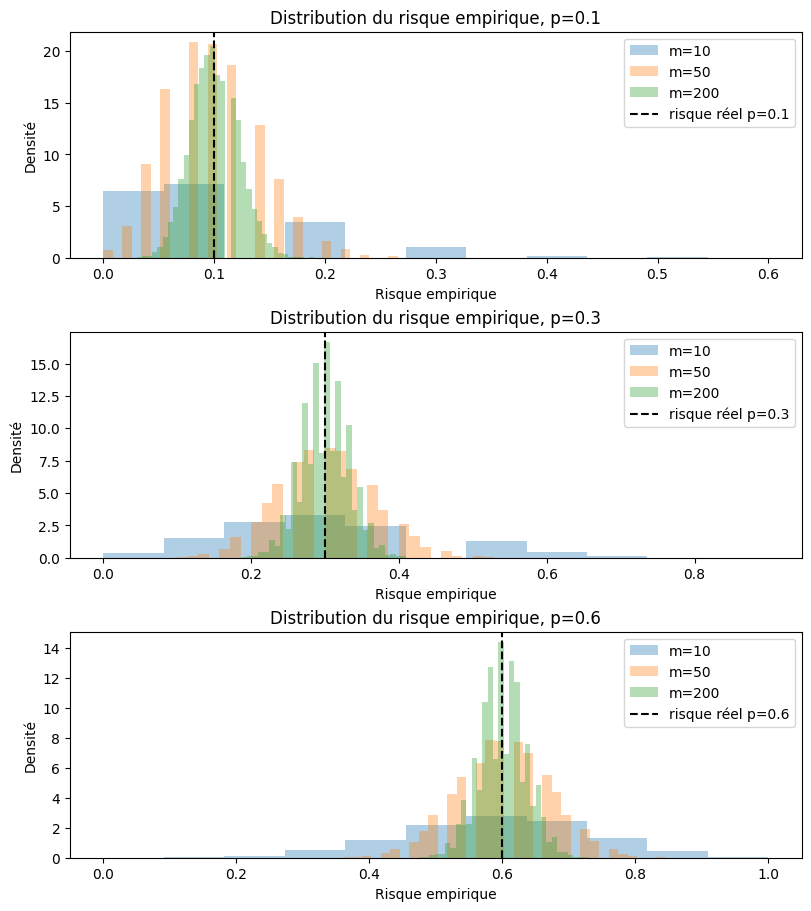

In [ ]:
p_values = [0.1, 0.3, 0.6]
sample_sizes = [10, 50, 200]
R = 10000

fig, axes = plt.subplots(len(p_values), 1, figsize=(8, 9), constrained_layout=True)
for ax, p in zip(axes, p_values):
    for m in sample_sizes:
        empirical = rng.binomial(m, p, size=R) / m
        ax.hist(empirical, bins=min(m + 1, 35), density=True, alpha=0.35,
                label=f"m={m}")
        print(f"p={p:.1f}, m={m:3d}: moyenne empirique={empirical.mean():.4f}, "
              f"moyenne théorique={p:.4f}, écart-type empirique={empirical.std():.4f}")
    ax.axvline(p, color="black", linestyle="--", label=f"risque réel p={p}")
    ax.set_title(f"Distribution du risque empirique, p={p}")
    ax.set_xlabel("Risque empirique")
    ax.set_ylabel("Densité")
    ax.legend()
plt.show()

**Interprétation des résultats.** Pour les trois risques réels étudiés ($p=0{,}1$, $0{,}3$ et $0{,}6$), les moyennes empiriques restent proches de $p$. Pour $p=0{,}3$, elles valent respectivement **0,3008**, **0,3000** et **0,3002** lorsque $m=10$, $50$ et $200$. L'écart-type empirique diminue de **0,1452** à **0,0645**, puis **0,0324**. Les histogrammes se resserrent donc autour du risque réel. Cela correspond à $\mathbb E[L_S(h)]=p$ et $\mathrm{Var}(L_S(h))=p(1-p)/m$ : augmenter $m$ réduit les fluctuations sans changer l'espérance.

### 2. Écart entre le risque empirique et le risque réel

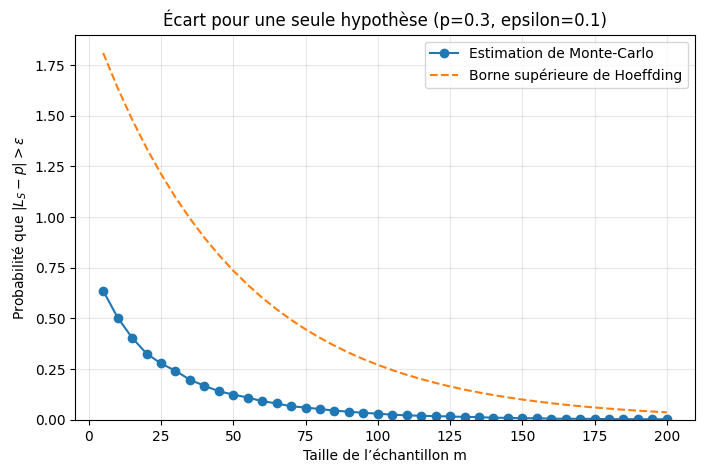

In [ ]:
p = 0.3
epsilon = 0.1
sample_sizes = np.arange(5, 201, 5)
R = 20000
experimental_probs = []

for m in sample_sizes:
    empirical = rng.binomial(m, p, size=R) / m
    experimental_probs.append(np.mean(np.abs(empirical - p) > epsilon))

experimental_probs = np.array(experimental_probs)
hoeffding = 2 * np.exp(-2 * sample_sizes * epsilon**2)

plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, experimental_probs, "o-", label="Estimation de Monte-Carlo")
plt.plot(sample_sizes, hoeffding, "--", label="Borne supérieure de Hoeffding")
plt.xlabel("Taille de l’échantillon m")
plt.ylabel(r"Probabilité que $|L_S-p|>\epsilon$")
plt.title(f"Écart pour une seule hypothèse (p={p}, epsilon={epsilon})")
plt.ylim(bottom=0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Interprétation des résultats.** Pour $p=0{,}3$ et $\varepsilon=0{,}1$, la probabilité simulée $\Pr(|L_S-p|>\varepsilon)$ décroît globalement avec $m$, avec de légères fluctuations Monte-Carlo. La borne de Hoeffding $2e^{-2m\varepsilon^2}$ décroît elle aussi, mais reste généralement au-dessus de la probabilité observée. Pour de petits $m$, son expression peut même être supérieure à 1 : elle est alors valide mais non informative. La borne est donc **conservatrice**, et non une formule exacte de la probabilité.

### 3. D’une seule hypothèse à la convergence uniforme

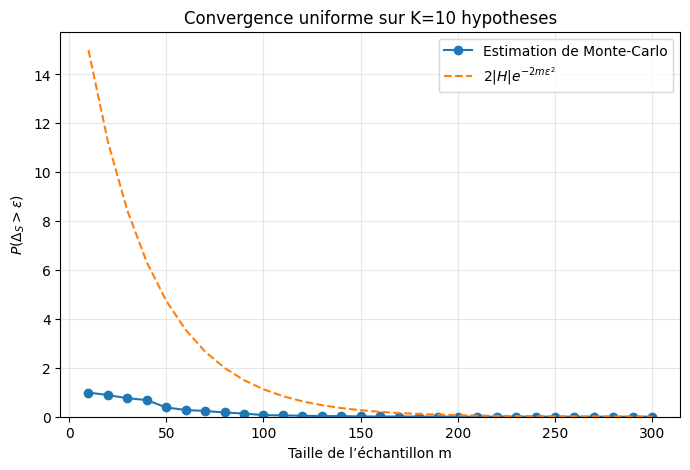

In [ ]:
p_values = np.array([0.1, 0.25, 0.4, 0.55, 0.7, 0.85, 0.3, 0.6, 0.2, 0.5])
K = len(p_values)
epsilon = 0.12
sample_sizes = np.arange(10, 301, 10)
R = 10000
uniform_probs = []

for m in sample_sizes:
    errors = rng.binomial(m, p_values, size=(R, K)) / m
    delta = np.max(np.abs(errors - p_values), axis=1)
    uniform_probs.append(np.mean(delta > epsilon))

uniform_probs = np.array(uniform_probs)
uniform_bound = 2 * K * np.exp(-2 * sample_sizes * epsilon**2)

plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, uniform_probs, "o-", label="Estimation de Monte-Carlo")
plt.plot(sample_sizes, uniform_bound, "--", label=r"$2|H|e^{-2m\epsilon^2}$")
plt.xlabel("Taille de l’échantillon m")
plt.ylabel(r"$P(\Delta_S>\epsilon)$")
plt.title(f"Convergence uniforme sur K={K} hypotheses")
plt.ylim(bottom=0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Interprétation des résultats.** Avec **$K=10$ hypothèses** et $\varepsilon=0{,}12$, la fréquence estimée de l'événement $\Delta_S=\max_{h\in H}|L_S(h)-L_D(h)|>\varepsilon$ décroît globalement quand $m$ augmente. Le contrôle est simultané : il suffit qu'une seule hypothèse dépasse le seuil pour que l'événement se produise. La borne $2|H|e^{-2m\varepsilon^2}$ reste conservatrice et peut dépasser 1 pour de petits échantillons. Les courbes illustrent donc la convergence uniforme.

### 4. Effet de la taille de la classe d’hypothèses

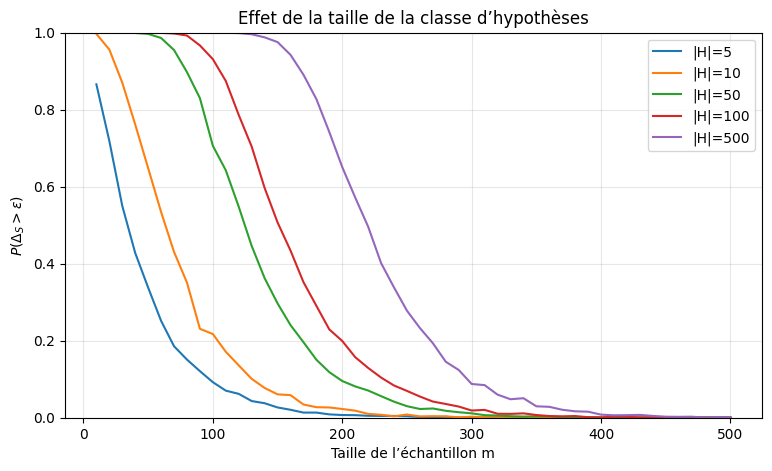

In [ ]:
epsilon = 0.1
class_sizes = [5, 10, 50, 100, 500]
sample_sizes = np.arange(10, 501, 10)
R = 3000
curves = {}

for K in class_sizes:
    # Fixed but varied risque réels in [0.1, 0.9]
    ps = np.linspace(0.1, 0.9, K)
    probs = []
    for m in sample_sizes:
        empirical = rng.binomial(m, ps, size=(R, K)) / m
        probs.append(np.mean(np.max(np.abs(empirical - ps), axis=1) > epsilon))
    curves[K] = np.array(probs)

plt.figure(figsize=(9, 5))
for K, probs in curves.items():
    plt.plot(sample_sizes, probs, label=f"|H|={K}")
plt.xlabel("Taille de l’échantillon m")
plt.ylabel(r"$P(\Delta_S>\epsilon)$")
plt.title("Effet de la taille de la classe d’hypothèses")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Interprétation des résultats.** Les courbes pour $|H|=5,10,50,100,500$ montrent que, à $m$ fixé, la probabilité d'un écart maximal supérieur à $\varepsilon=0{,}1$ tend à être plus élevée lorsque la classe contient davantage d'hypothèses. Toutes les courbes diminuent globalement avec $m$ : une classe plus grande demande généralement davantage de données pour le même contrôle simultané. La garantie théorique fait intervenir $\log |H|$ dans la complexité d'échantillonnage : cette dépendance est **logarithmique**, pas linéaire.

### 5. Complexité d’échantillonnage expérimentale

Plus petite valeur de m testée telle que P(Delta_S > epsilon) estimée soit <= delta : 240
Taille d’échantillon théorique suffisante : 381


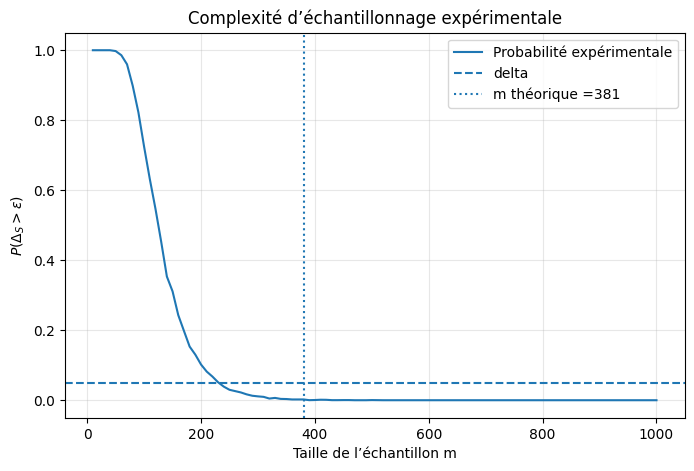

In [ ]:
epsilon = 0.1
delta = 0.05
K = 50
ps = np.linspace(0.1, 0.9, K)
sample_sizes = np.arange(10, 1001, 10)
R = 5000
first_m = None
observed = []

for m in sample_sizes:
    empirical = rng.binomial(m, ps, size=(R, K)) / m
    prob = np.mean(np.max(np.abs(empirical - ps), axis=1) > epsilon)
    observed.append(prob)
    if first_m is None and prob <= delta:
        first_m = m

theoretical_m = math.ceil(math.log(2 * K / delta) / (2 * epsilon**2))
print("Plus petite valeur de m testée telle que P(Delta_S > epsilon) estimée soit <= delta :", first_m)
print("Taille d’échantillon théorique suffisante :", theoretical_m)
plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, observed, label="Probabilité expérimentale")
plt.axhline(delta, linestyle="--", label="delta")
plt.axvline(theoretical_m, linestyle=":", label=f"m théorique ={theoretical_m}")
plt.xlabel("Taille de l’échantillon m")
plt.ylabel(r"$P(\Delta_S>\epsilon)$")
plt.title("Complexité d’échantillonnage expérimentale")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Interprétation des résultats.** Pour $\varepsilon=0{,}1$, $\delta=0{,}05$ et $|H|=50$, la **plus petite taille testée** satisfaisant la condition expérimentale $\widehat{\Pr}(\Delta_S>\varepsilon)\leq\delta$ est **$m=240$**. La borne théorique donne $m\geq\ln(2|H|/\delta)/(2\varepsilon^2)$, soit **381 observations** après arrondi supérieur. L'écart est de **141 observations**. La borne est une garantie suffisante et conservatrice, non la taille minimale exacte. La valeur expérimentale dépend des tailles testées et du nombre de répétitions.

## Partie II — Simulation du principe

### 6. Entrées observées et non observées

In [ ]:
def simulate_unseen_fraction(N, m, repetitions=5000):
    fractions = []
    for _ in range(repetitions):
        x_train = rng.integers(0, N, size=m)
        seen = np.zeros(N, dtype=bool)
        seen[x_train] = True
        fractions.append(np.mean(~seen))
    return np.mean(fractions)

Ns = [20, 100, 500]
ms = [5, 20, 50, 100]
for N in Ns:
    for m in ms:
        if m > 0:
            empirical = simulate_unseen_fraction(N, m)
            theoretical = (1 - 1/N)**m
            print(f"N={N:3d}, m={m:3d}: fraction non observée empirique={empirical:.4f}, "
                  f"théorique={theoretical:.4f}")

N= 20, m=  5: fraction non observée empirique=0.7738, théorique=0.7738
N= 20, m= 20: fraction non observée empirique=0.3571, théorique=0.3585
N= 20, m= 50: fraction non observée empirique=0.0772, théorique=0.0769
N= 20, m=100: fraction non observée empirique=0.0060, théorique=0.0059
N=100, m=  5: fraction non observée empirique=0.9511, théorique=0.9510
N=100, m= 20: fraction non observée empirique=0.8175, théorique=0.8179
N=100, m= 50: fraction non observée empirique=0.6048, théorique=0.6050
N=100, m=100: fraction non observée empirique=0.3661, théorique=0.3660
N=500, m=  5: fraction non observée empirique=0.9900, théorique=0.9900
N=500, m= 20: fraction non observée empirique=0.9607, théorique=0.9608
N=500, m= 50: fraction non observée empirique=0.9047, théorique=0.9047
N=500, m=100: fraction non observée empirique=0.8185, théorique=0.8186


**Démonstration et interprétation des résultats.** Un point $x$ donné n'est pas tiré lors d'une observation avec probabilité $1-1/N$; après $m$ tirages indépendants, $\Pr(x\text{ non observé})=(1-1/N)^m$. La fraction de points non observés est une moyenne d'indicatrices, donc son espérance est cette même probabilité par linéarité de l'espérance.

Les résultats concordent avec la formule : pour **$N=100$**, les fractions expérimentales valent **0,9511**, **0,8175**, **0,6048**, **0,3661** pour $m=5,20,50,100$, contre **0,9510**, **0,8179**, **0,6050**, **0,3660** théoriquement. À $m=100$, la fraction expérimentale passe de **0,0060** pour $N=20$ à **0,8185** pour $N=500$. Une taille de domaine plus grande nécessite donc plus de tirages pour couvrir une proportion comparable de points.

### 7. Erreur sur les entrées non observées

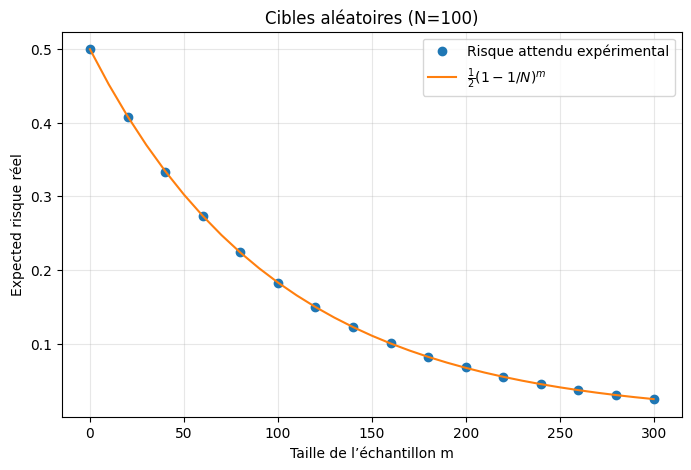

In [ ]:
def random_target_risk(N, m, repetitions=5000):
    risks = []
    for _ in range(repetitions):
        target = rng.integers(0, 2, size=N)
        x_train = rng.integers(0, N, size=m)
        y_train = target[x_train]
        # Mémoriser les étiquettes observées ; prédire 0 pour les points inconnus.
        prediction = np.zeros(N, dtype=int)
        seen = np.zeros(N, dtype=bool)
        for x, y in zip(x_train, y_train):
            seen[x] = True
            prediction[x] = y
        risks.append(np.mean(prediction != target))
    return np.mean(risks)

N = 100
sample_sizes = np.arange(0, 301, 10)
R = 3000
experimental = np.array([random_target_risk(N, int(m), R) for m in sample_sizes])
theoretical = 0.5 * (1 - 1/N)**sample_sizes

plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, experimental, "o", markevery=2, label="Risque attendu expérimental")
plt.plot(sample_sizes, theoretical, "-", label=r"$\frac{1}{2}(1-1/N)^m$")
plt.xlabel("Taille de l’échantillon m")
plt.ylabel("Expected risque réel")
plt.title(f"Cibles aléatoires (N={N})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Démonstration et interprétation des résultats.** Les points observés sont mémorisés et prédits sans erreur. Sur chaque point non observé, l'étiquette cible est une Bernoulli$(1/2)$ indépendante : prédire 0 conduit donc à une erreur moyenne de $1/2$. En combinant cela avec la fraction moyenne de points non observés :

$$\mathbb E[L_D(A(S))]=\frac12\left(1-\frac1N\right)^m.$$

Pour **$N=100$**, la courbe expérimentale du risque moyen suit de près cette prédiction théorique et décroît avec $m$. Au départ ($m=0$), le risque attendu est **0,5**; lorsque davantage de points sont mémorisés, il diminue. Mais les étiquettes des points non vus restent imprévisibles à partir de l'échantillon.

### 8. Modifier la prédiction pour les entrées non observées

In [ ]:
def risk_for_unseen_rule(N, m, rule, repetitions=5000):
    risks = []
    for _ in range(repetitions):
        target = rng.integers(0, 2, size=N)
        x_train = rng.integers(0, N, size=m)
        prediction = np.zeros(N, dtype=int)
        seen = np.zeros(N, dtype=bool)
        for x in x_train:
            seen[x] = True
            prediction[x] = target[x]
        unseen = ~seen
        if rule == "toujours 0":
            prediction[unseen] = 0
        elif rule == "toujours 1":
            prediction[unseen] = 1
        elif rule == "random":
            prediction[unseen] = rng.integers(0, 2, size=np.sum(unseen))
        risks.append(np.mean(prediction != target))
    return np.mean(risks)

N, m = 100, 30
for rule in ["toujours 0", "toujours 1", "random"]:
    print(f"{rule:>10}: risque réel moyen estimé = "
          f"{risk_for_unseen_rule(N, m, rule):.4f}")
print("Risque théorique attendu pour chaque règle :", 0.5 * (1 - 1/N)**m)

toujours 0: risque réel moyen estimé = 0.3697
toujours 1: risque réel moyen estimé = 0.3691
    random: risque réel moyen estimé = 0.3707
Risque théorique attendu pour chaque règle : 0.3698501866941401


**Interprétation des résultats.** Pour **$N=100$** et **$m=30$**, les risques moyens obtenus sont **0,3697** (toujours 0), **0,3691** (toujours 1) et **0,3707** (prédiction aléatoire), à comparer à la valeur théorique commune **0,36985**. Les écarts sont faibles et dus aux fluctuations de simulation : la règle « toujours 1 » n'est pas systématiquement meilleure. Les étiquettes inconnues étant indépendantes et équiprobables, aucune de ces stratégies ne peut exploiter l'échantillon pour mieux les prédire en moyenne. C'est l'illustration du principe **No-Free-Lunch** dans ce cadre.

## Partie III


### 9. Apprentissage avec un biais inductif adapté (ERM)

In [ ]:
def threshold_risk(N, theta, t):
    x = np.arange(1, N + 1)
    target = (x > theta).astype(int)
    pred = (x > t).astype(int)
    return np.mean(pred != target)

def erm_threshold(N, x_train, y_train):
    # Parcourir tous les seuils candidats et minimiser l’erreur empirique 0-1.
    candidates = np.arange(1, N)
    losses = []
    for t in candidates:
        pred = (x_train > t).astype(int)
        losses.append(np.mean(pred != y_train))
    # En cas d’égalité entre plusieurs seuils, choisir le premier minimiseur.
    return int(candidates[np.argmin(losses)])

def simulate_threshold_learning(N, m, repetitions=3000):
    risks = []
    for _ in range(repetitions):
        theta = int(rng.integers(1, N))
        x_train = rng.integers(1, N + 1, size=m)
        y_train = (x_train > theta).astype(int)
        t_hat = erm_threshold(N, x_train, y_train)
        risks.append(threshold_risk(N, theta, t_hat))
    return np.mean(risks)

N = 100
sample_sizes = [2, 5, 10, 20, 50, 100, 200]
for m in sample_sizes:
    print(f"m={m:3d}: estimated expected risque réel = "
          f"{simulate_threshold_learning(N, m):.4f}")

m=  2: estimated expected risque réel = 0.2436
m=  5: estimated expected risque réel = 0.1390
m= 10: estimated expected risque réel = 0.0784
m= 20: estimated expected risque réel = 0.0401
m= 50: estimated expected risque réel = 0.0143
m=100: estimated expected risque réel = 0.0055
m=200: estimated expected risque réel = 0.0015


**Interprétation des résultats.** Pour la cible structurée $f_\theta(x)=\mathbf 1[x>\theta]$, l'ERM sélectionne un seuil minimisant les erreurs sur l'échantillon. Les risques réels moyens simulés diminuent fortement : **0,2436** ($m=2$), **0,1390** ($m=5$), **0,0784** ($m=10$), **0,0401** ($m=20$), **0,0143** ($m=50$), **0,0055** ($m=100$), **0,0015** ($m=200$). La classe d'hypothèses contient la vraie cible; les observations contraignent donc la position du seuil, ce qui permet de généraliser sur des points non observés. Cette amélioration illustre l'intérêt d'un **biais inductif adapté**.

### 10. Cibles aléatoires et cibles structurées

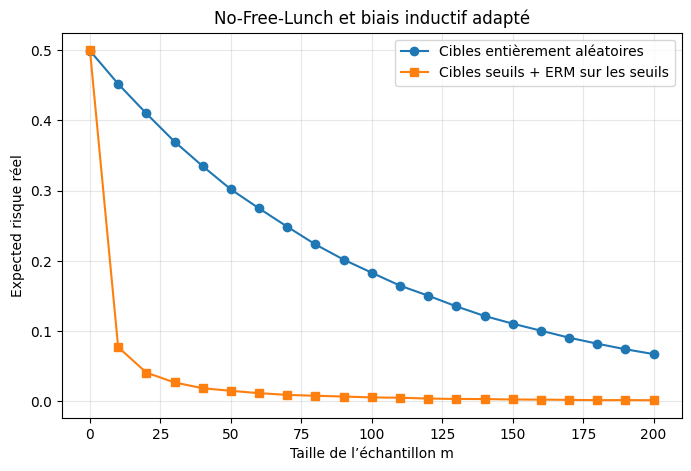

In [ ]:
N = 100
sample_sizes = np.arange(0, 201, 10)
R = 2000
random_risks = np.array([random_target_risk(N, int(m), R) for m in sample_sizes])
threshold_risks = np.array([
    simulate_threshold_learning(N, int(m), R) if m > 0 else 0.5
    for m in sample_sizes
])

plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, random_risks, "o-", label="Cibles entièrement aléatoires")
plt.plot(sample_sizes, threshold_risks, "s-", label="Cibles seuils + ERM sur les seuils")
plt.xlabel("Taille de l’échantillon m")
plt.ylabel("Expected risque réel")
plt.title("No-Free-Lunch et biais inductif adapté")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Interprétation des résultats.** Le graphique compare, sur le même domaine, les cibles entièrement aléatoires apprises par mémorisation et les cibles structurées apprises par ERM sur les seuils. Les deux risques diminuent avec $m$, mais la décroissance est **nettement plus rapide pour les seuils**. Pour une cible aléatoire, les étiquettes non observées sont indépendantes de celles vues : il faut essentiellement mémoriser les points. Pour une cible seuil, quelques observations permettent de restreindre les positions possibles de la frontière et de prédire d'autres points. La meilleure généralisation vient donc de l'hypothèse structurante $f\in H$.

**Précaution :** dans le code, la valeur de risque **0,5 à $m=0$** pour la courbe des seuils est fixée manuellement; ce point n'est pas une mesure expérimentale et ne doit pas être interprété comme tel.

### 11. Analyse finale

**Conclusion générale**

1. **Concentration du risque empirique.** Les moyennes simulées restent proches du risque réel, tandis que l'écart-type diminue avec $m$ (pour $p=0{,}3$, de **0,1452** à $m=10$ à **0,0324** à $m=200$), conformément à $\mathrm{Var}(L_S)=p(1-p)/m$.
2. **Convergence uniforme.** Il faut contrôler le plus grand écart parmi **toutes** les hypothèses. Une classe plus grande augmente généralement la probabilité d'au moins un écart important et nécessite davantage de données; la borne fait apparaître $\log|H|$.
3. **Bornes conservatrices.** Pour $\varepsilon=0{,}1$, $\delta=0{,}05$ et $|H|=50$, le seuil expérimental parmi les tailles testées est **240**, contre **381** pour la garantie théorique suffisante : celle-ci n'est pas nécessairement optimale.
4. **No-Free-Lunch.** Les étiquettes des points non observés sont imprévisibles lorsque les cibles sont entièrement aléatoires. Les risques **0,3697**, **0,3691** et **0,3707** des trois stratégies restent voisins de l'espérance théorique **0,36985** : aucune règle ne gagne systématiquement.
5. **Biais inductif.** Lorsque les cibles et les hypothèses sont des fonctions seuil, l'ERM exploite cette structure pour généraliser : son risque moyen passe de **0,2436** pour $m=2$ à **0,0015** pour $m=200$.

**résumé** La quantité de données favorise la concentration et la convergence uniforme, mais une bonne généralisation dépend aussi des hypothèses structurelles choisies. Les valeurs expérimentales sont des estimations Monte-Carlo; elles peuvent varier légèrement lors d'une nouvelle exécution.